The piecewise function $f(t)$ is defined on the interval -1 $\le t \le$ 1.

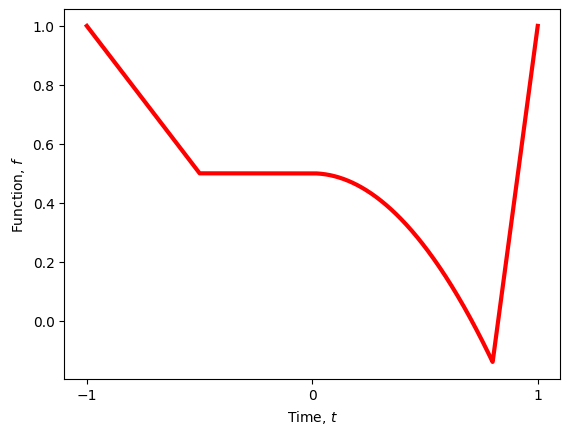

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def f(t):
    if t < -0.5:
        f = -t
    elif t < 0:
        f = 0.5
    elif t < 0.8:
        f = -t**2 + 0.5
    else:
        t1,f1 = 0.8, 0.5 - 0.8**2
        t2,f2 = 1.0, 1.0
        m = (f2-f1)/(t2-t1)
        b = f2 - m * t2
        f =  m * t + b
    return f
    
tmin, tmax, Npts = -1,1,1000
td = np.linspace(tmin,tmax,Npts)
fd = np.zeros_like(td)
for it,ti in enumerate(td):
    fd[it] = f(ti)

plt.plot(td,fd,'r-',lw=3)
plt.xticks((-1,0,1))
plt.xlabel('Time, $t$')
plt.ylabel('Function, $f$')
plt.show()

Fit the following series to $f(t)$:

- a 10th order power series polynomial
- a 200th order Chebyshev polynomial
- a Fourier series with 15 sin and cos terms, not including the constant

Plot all of your fits along with the original function.

Sample output, for a different underlying function, is given below:

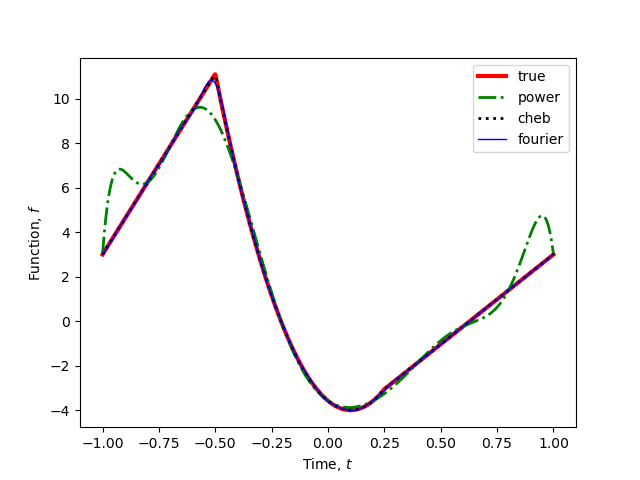

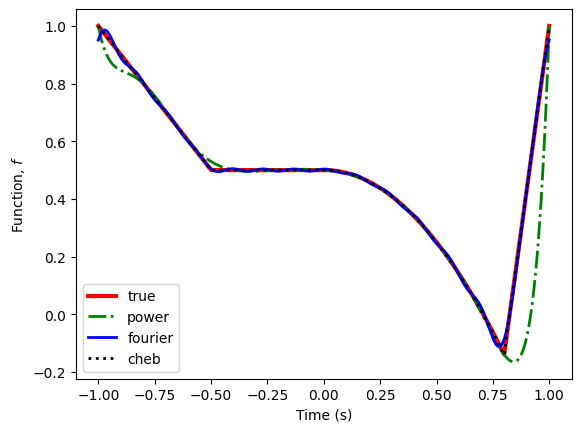

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import numpy.polynomial.polynomial as pp
import numpy.polynomial.chebyshev as pc
import scipy.optimize as opt
import scipy.integrate as intx

## 10th Order Power Series Polynomial ##
# order of the polynomial
n = 10
# choose n+1 evenly spaced points
x = np.linspace(-1,1,n+1)
# evaluate
f_vec = np.vectorize(f)  # applies function designed for single values (Piecewise) to each element without explicitly writing a loop 
y = f_vec(x)
# fit polynomial
p = pp.polyfit(x,y,n)

# look at fit
xd = np.linspace(-1,1,1000)
plt.plot(xd,f_vec(xd),'r-',lw=3,label='true')
plt.plot(xd,pp.polyval(xd,p),'g-.',lw=2,label='power')

## 200th Order Chebyshev Polynomial ##
# order of polynomial
n = 200
# n+1 points
x = pc.chebpts2(n+1)
p = pc.chebfit(x,f_vec(x),n)

## Fourier Series 15th terms

Nmax = 15
a = np.zeros(Nmax)
b = np.zeros(Nmax)

#Period of Function
T = 2 
t0 = -1
t1 = np.linspace(t0,t0+T,1000)
t = np.linspace(t0,t0+T,1000)

a[0] = 2/T * intx.quad(f,t0,t0+T)[0]

for n in range(1,Nmax):
    a[n] = 2/T * intx.quad(lambda t: f(t)*np.cos(2*np.pi*n*t/T),t0,t0+T)[0]
    b[n] = 2/T * intx.quad(lambda t: f(t)*np.sin(2*np.pi*n*t/T),t0,t0+T)[0]

y = np.zeros_like(t1) + a[0]/2
for n in range(1,Nmax):
    y += a[n]*np.cos(2*np.pi*n*t1/T) + b[n]*np.sin(2*np.pi*n*t1/T)
    
# plot
plt.plot(t1,y,'b-',lw=2,label='fourier')
plt.plot(xd,pc.chebval(xd,p),":",color='black',lw=2,label='cheb')
plt.legend(fontsize=10,loc='lower left')
plt.xlabel('Time (s)')
plt.ylabel('Function, $f$')
plt.show()